# 01 · Logits to text

**The question.** When a language model "writes", what does the model actually do, and what is done *to* its output afterwards?

**The claim.** The model does one thing. Given the text so far, it produces a score (a *logit*) for every token in its vocabulary. That vector is its complete, fixed opinion about what comes next. Turning that opinion into an actual token is a separate, tiny procedure, the **decoder** (or sampler), and it is entirely under your control.

**By the end** you will be able to point at the exact line where the model stops and decoding begins, and the central experiment of this project will be set up: *one fixed distribution, many decoders.*

*Outputs:* figures go to `outputs/figures/01_*.png`, the numbers and text behind them to `outputs/results/01_*.json`.

In [1]:
import inspect
import textwrap

import pandas as pd
import torch

from src.config import get_settings

S = get_settings()
SEED = S.seed
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 160)
print(f"seed = {SEED}  (config/settings.yaml)")

from src.results import save_json
from src.visualisation import save_figure

seed = 42  (config/settings.yaml)


## 1. A model small enough to read in full

Two models are used throughout. The first is built from scratch: a character-level language model (an MLP over the last 8 characters) trained for a few seconds on a small built-in corpus of stories and facts. Its vocabulary is about 30 characters, so its *entire* next-token distribution fits on one chart. The second, in section 5, is `distilgpt2`, a small real model with a 50,257-token vocabulary.

In [2]:
from src.datasets.corpus import TINY_CORPUS
from src.model import default_char_lm

model = default_char_lm()  # trained once per process, seeded from config/settings.yaml
model_info = {
    "corpus_characters": len(TINY_CORPUS),
    "vocab_size": model.vocab_size,
    "alphabet": model.token_labels(range(model.vocab_size)),
    "context_characters": model.context,
    "parameters": sum(p.numel() for p in model.parameters()),
    "train_steps": len(model.train_loss),
    "loss_first_step_nats": model.train_loss[0],
    "loss_last_50_mean_nats": sum(model.train_loss[-50:]) / 50,
    "settings": S.char_lm.model_dump(),
}
save_json("01_char_model", model_info)
print(f"corpus {model_info['corpus_characters']:,} chars | vocab {model.vocab_size} | "
      f"context {model.context} | {model_info['parameters']:,} parameters")
print("alphabet:", " ".join(model_info["alphabet"]))
print(f"training loss: {model_info['loss_first_step_nats']:.2f} -> "
      f"{model_info['loss_last_50_mean_nats']:.3f} nats/char over {model_info['train_steps']} steps")

corpus 7,663 chars | vocab 29 | context 8 | 57,557 parameters
alphabet: ↵ ␣ , . a b c d e f g h i j k l m n o p q r s t u v w x y
training loss: 3.41 -> 0.113 nats/char over 1500 steps


## 2. Run the model once

Give it a prompt and read off its output: one logit per token in the vocabulary. Nothing has been chosen yet.

In [3]:
from src.analysis import entropy, top_tokens
from src.model import next_token_logits

prompt = "the keeper "
logits = next_token_logits(model, prompt)  # (1, vocab): the model's complete opinion
print("logits shape:", tuple(logits.shape))
table = top_tokens(model, logits, n=model.vocab_size)
table.head(12).round(4)

logits shape: (1, 29)


,rank,token_id,token,logit,prob
0,1,6,c,6.5218,0.2140
1,2,22,s,6.4375,0.1967
2,3,11,h,6.0336,0.1313
3,4,15,l,5.9292,0.1183
4,5,10,g,5.9033,0.1153
5,6,26,w,5.8948,0.1143
6,7,4,a,5.7264,0.0966
7,8,9,f,2.3684,0.0034
8,9,23,t,2.3295,0.0032
9,10,18,o,1.6416,0.0016


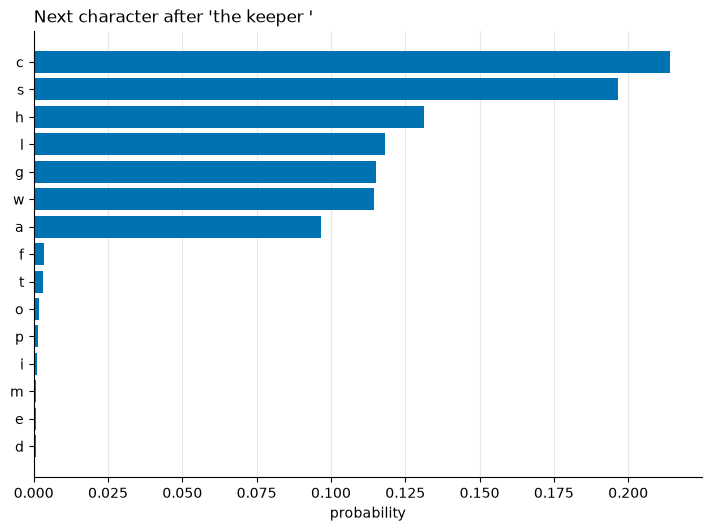

In [4]:
from src.visualisation import plot_top_tokens

fig = plot_top_tokens(table.head(15), title=f"Next character after {prompt!r}")
save_figure(fig, "01_next_token_distribution")
save_json("01_next_token_distribution", {
    "model": model.name,
    "prompt": prompt,
    "entropy_bits": entropy(logits, base=2).item(),
    "uniform_entropy_bits": float(torch.log2(torch.tensor(float(model.vocab_size)))),
    "full_distribution": table,
});

## 3. Softmax: from scores to probabilities

Logits are unbounded scores. The softmax turns them into a probability distribution: exponentiate, then normalise. Subtracting the maximum first changes nothing mathematically and keeps `exp` from overflowing.

$$p_i = \frac{e^{z_i - \max z}}{\sum_j e^{z_j - \max z}}$$

In [5]:
z = logits[0]
by_hand = torch.exp(z - z.max()) / torch.exp(z - z.max()).sum()
torch.testing.assert_close(by_hand, torch.softmax(z, dim=-1))
top = model.token_labels([int(by_hand.argmax())])[0]
print(f"sums to {by_hand.sum():.6f}; most likely next character {top!r} with p = {by_hand.max():.3f}")
print(f"entropy {entropy(logits, base=2).item():.2f} bits "
      f"(uniform over {model.vocab_size} would be {torch.log2(torch.tensor(float(model.vocab_size))):.2f})")

sums to 1.000000; most likely next character 'c' with p = 0.214
entropy 2.85 bits (uniform over 29 would be 4.86)


**This is where the model's job ends.** Everything below operates on that one vector. The model is not consulted about *how* to pick from it.

## 4. Same distribution, different pickers

Pick the next character from the identical distribution four ways: always the most likely (greedy), or sample from it with three different seeds.

In [6]:
from src.decoders import Decoder, make_generator

ids = model.encode(prompt)
pickers = {"greedy": (Decoder.greedy(), None)} | {
    f"sample, seed {s}": (Decoder.sampling(1.0), make_generator(s)) for s in range(3)
}
picks = {}
for name, (decoder, generator) in pickers.items():
    picks[name] = model.token_labels([int(decoder(logits, ids, generator))])[0]
    print(f"{name:16s} -> {picks[name]!r}")

greedy           -> 'c'
sample, seed 0   -> 's'
sample, seed 1   -> 'l'
sample, seed 2   -> 'c'


Repeat that single step a few hundred times, feeding each pick back in as input, and you have text generation. The loop lives in `src/decoders/__init__.py`, and this is all of it:

In [7]:
from src.decoders import generate

lines = inspect.getsource(generate).splitlines()
print("\n".join(lines[lines.index("    ids = input_ids") :]))

    ids = input_ids
    finished = torch.zeros(ids.size(0), dtype=torch.bool)
    for _ in range(max_new_tokens):
        next_ids = decoder(model.next_token_logits(ids), ids, generator)
        if eos_token_id is not None:
            next_ids = torch.where(finished[:, None], eos_token_id, next_ids)
            finished |= next_ids.squeeze(-1) == eos_token_id
        ids = torch.cat([ids, next_ids], dim=-1)
        if bool(finished.all()):
            break
    return ids


In [8]:
generations = {}
for decoder in [Decoder.greedy(), Decoder.nucleus(0.8)]:
    out = decoder.generate(model, ids, 160, generator=make_generator(SEED))
    generations[decoder.label] = model.decode(out[0, ids.size(1):])
    print(f"--- {decoder.label}\n{prompt}{generations[decoder.label]}\n")
save_json("01_pickers_and_generations", {
    "prompt": prompt, "one_step_picks": picks, "max_new_tokens": 160, "generations": generations,
});

--- greedy
the keeper climbed the stairs for the market was held on the days when his boat came out of the sea. in the morning and the small white boat that belonged to the sea. in t

--- T=1, top-p=0.8
the keeper grew old and the light showed it the way.

the capital of egypt is cairo.
the capital of norway is oslo.
the capital of egypt is cairo.
the capital of spain is 



Same model, same prompt, same starting distribution. Greedy is already circling back on itself, while nucleus sampling (`top-p`) wanders through the corpus's vocabulary. Notebook 02 takes the loop apart.

## 5. A real model: the same picture

`distilgpt2` (82M parameters) has a vocabulary of 50,257 subword tokens. Its output is still one vector of logits, just a much longer one.

In [9]:
from huggingface_hub.utils import logging as hub_logging
from transformers.utils import logging as hf_logging

from src.model import load_model

hf_logging.set_verbosity_error()
hf_logging.disable_progress_bar()
hub_logging.set_verbosity_error()
hf = load_model("hf")  # distilgpt2: ~350 MB on first use, cached afterwards

distilgpt2: vocabulary 50,257, logits shape (1, 50257), entropy 8.43 bits


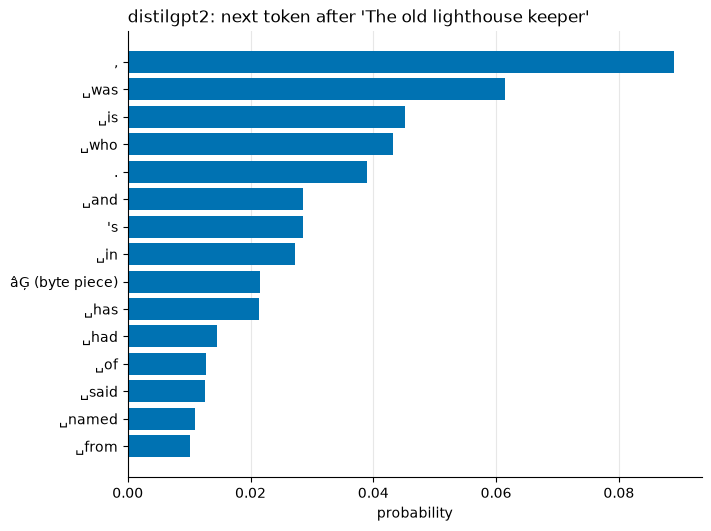

In [10]:
hf_prompt = "The old lighthouse keeper"
hf_logits = next_token_logits(hf, hf_prompt)
hf_table = top_tokens(hf, hf_logits, n=15)
hf_entropy = entropy(hf_logits, base=2).item()
print(f"{hf.name}: vocabulary {hf.vocab_size:,}, logits shape {tuple(hf_logits.shape)}, "
      f"entropy {hf_entropy:.2f} bits")
fig = plot_top_tokens(hf_table, title=f"{hf.name}: next token after {hf_prompt!r}")
save_figure(fig, "01_distilgpt2_distribution")
save_json("01_distilgpt2_distribution", {
    "model": hf.name, "prompt": hf_prompt, "vocab_size": hf.vocab_size,
    "entropy_bits": hf_entropy, "top_15": hf_table,
});

The tokens are subwords, with `␣` marking a leading space: the decoder chooses among *tokens*, not words (see `tokenization_101`).

## 6. The central experiment: one fixed distribution, many decoders

Hold the logits fixed and pass them through different decoders. Every panel below is the *same* model output; only the decoding settings differ. Grey bars with a red × were removed by the decoder.

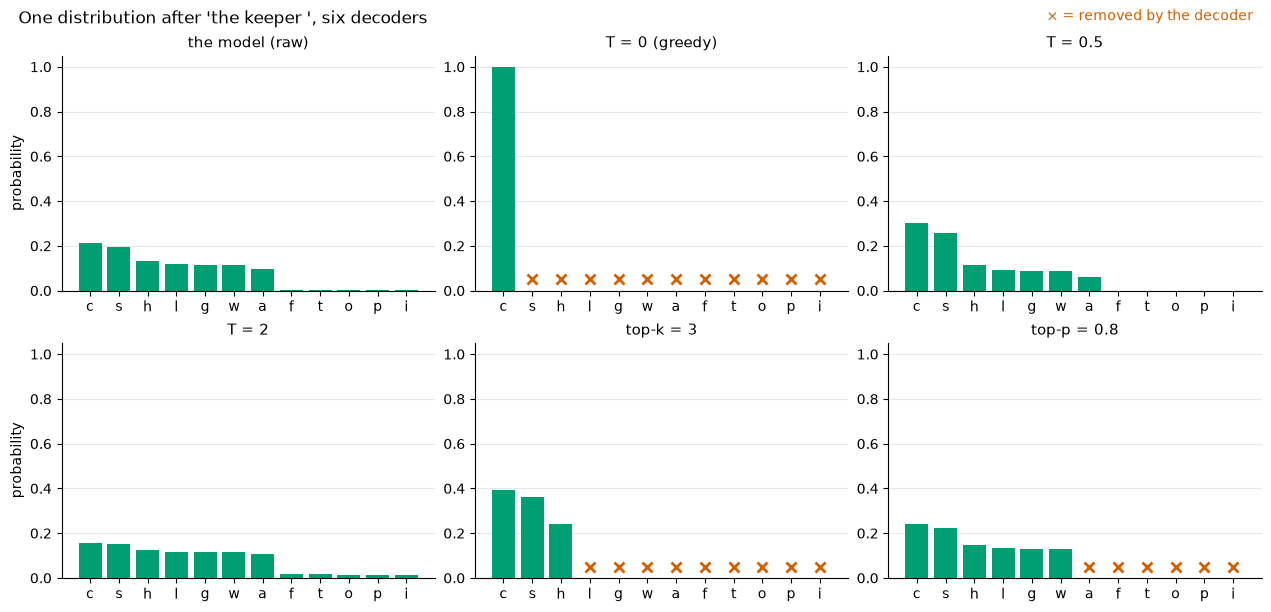

In [11]:
from src.visualisation import plot_reshaped_distributions

decoders = {
    "the model (raw)": Decoder(),
    "T = 0 (greedy)": Decoder.greedy(),
    "T = 0.5": Decoder.sampling(0.5),
    "T = 2": Decoder.sampling(2.0),
    "top-k = 3": Decoder.top_k_sampling(3),
    "top-p = 0.8": Decoder.nucleus(0.8),
}
warped = {name: d.warp(logits, ids) for name, d in decoders.items()}
fig = plot_reshaped_distributions(model, logits, warped, n=12,
                                  title=f"One distribution after {prompt!r}, six decoders")
save_figure(fig, "01_one_distribution_many_decoders")
shown = table.head(12)
save_json("01_one_distribution_many_decoders", {
    "prompt": prompt,
    "tokens": shown["token"],
    "probabilities": {
        name: dict(zip(shown["token"], torch.softmax(w, dim=-1)[0, shown["token_id"]].tolist()))
        for name, w in warped.items()
    },
    "tokens_kept": {name: int(torch.isfinite(w).sum()) for name, w in warped.items()},
});

## What this bought you

- The model's output is a vector of logits, one per token. It is computed once, and then it is fixed.
- Softmax turns logits into probabilities. That is the last step that is unambiguously "the model".
- Choosing a token is a separate step with its own code. Greedy, sampling, and every knob you have seen in an API (temperature, top-k, top-p) live *here*, not in the weights.

Next: [02 · Greedy and the loop](02_greedy_and_the_loop.ipynb), the simplest decoder and the most famous failure that is not the model's fault.